# Кейс 3. Бинарная классификация отклика клиентов на банковский депозит.

In [1]:
# 1. Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score, 
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

# Настройка графиков
plt.rcParams['figure.figsize'] = (18, 5)

In [2]:
# 2. Загрузка данных
try:
    df = pd.read_csv('bank-additional-full.csv', sep=None, engine='python')
except FileNotFoundError as e:
    raise FileNotFoundError("Файл 'bank-additional-full.csv' не найден.") from e

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
print("1. Проверка дубликатов")
duplicates_count = df.duplicated().sum()
print(f"Найдено полных дубликатов строк: {duplicates_count}")

# Удаляем полные дубликаты, если они есть
if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Дубликаты успешно удалены.\n")
else:
    print("Дубликатов нет.\n")

print("2. Проверка стандартных пропусков (NaN)")
# Считаем количество NaN по каждой колонке
missing_values = df.isna().sum()
missing_values = missing_values[missing_values > 0]

if not missing_values.empty:
    print("Найдены пропуски (NaN) в колонках:")
    print(missing_values)
else:
    print("Стандартных пропусков (NaN) не найдено.\n")

print("3. Проверка скрытых пропусков ('unknown')")
# Ищем строковые значения 'unknown'
unknown_counts = (df == 'unknown').sum()
unknown_counts = unknown_counts[unknown_counts > 0]

if not unknown_counts.empty:
    print("Найдены значения 'unknown' в колонках:")
    for col, count in unknown_counts.items():
        percentage = (count / len(df)) * 100
        print(f"{col}: {count} строк ({percentage:.2f}%)")
else:
    print("Значений 'unknown' не найдено.\n")

1. Проверка дубликатов
Найдено полных дубликатов строк: 12
Дубликаты успешно удалены.

2. Проверка стандартных пропусков (NaN)
Стандартных пропусков (NaN) не найдено.

3. Проверка скрытых пропусков ('unknown')
Найдены значения 'unknown' в колонках:
job: 330 строк (0.80%)
marital: 80 строк (0.19%)
education: 1730 строк (4.20%)
default: 8596 строк (20.88%)
housing: 990 строк (2.40%)
loan: 990 строк (2.40%)


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


In [6]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
# 3. Подготовка признаков (X) и целевой переменной (y)
X = df.drop('y', axis=1) # y
#X['is_contacted_before'] = (X['pdays'] != 999).astype(int)
y = (df['y'] == 'yes').astype(int)

# Определяем типы колонок
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
numerical_features = X.select_dtypes(exclude=['object', 'category', 'string']).columns.tolist()

In [ ]:
# 4. Пайплайн предобработки данных
preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features)
])

# 5. Пайплайн модели (используем solver='saga', так как он поддерживает и L1, и L2 регуляризацию)
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='saga', max_iter=2000, random_state=42))
])

In [9]:
# 6. Разбиение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

In [10]:
# Настройка гиперпараметров:
# Задаем сетку параметров для перебора
param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10],            # Сила регуляризации
    'classifier__l1_ratio': [1.0, 0.0],               # Тип штрафа
    'classifier__class_weight': ['balanced', None]    # Балансировка классов
}

print("Поиск оптимальных гиперпараметров (GridSearchCV)...")
# scoring='average_precision' максимизирует PR-AUC, что идеально для поиска откликов (1)
grid_search = GridSearchCV(
    pipeline, 
    param_grid=param_grid, 
    cv=3,                               # 3 фолда кросс-валидации для скорости
    scoring='average_precision',        # Оптимизируем под метрику PR-AUC
    n_jobs=-1,                          # Используем все ядра процессора
    verbose=1                           # Вывод прогресса
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print("\nЛучшие гиперпараметры")
for param, value in grid_search.best_params_.items():
    print(f"{param.replace('classifier__', '')}: {value}")

Поиск оптимальных гиперпараметров (GridSearchCV)...
Fitting 3 folds for each of 16 candidates, totalling 48 fits

Лучшие гиперпараметры
C: 1.0
class_weight: None
l1_ratio: 1.0


In [11]:
# 7. Предсказание на лучшей модели
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

In [12]:
# 8. Оценка бизнес-метрик
print("\nОтчет о классификации")
print(classification_report(y_test, y_pred, target_names=["Отказ (0)", "Согласие (1)"]))

# Специфичные метрики для дисбаланса
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba) # Это и есть площадь под PR-кривой

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC (Average Precision): {pr_auc:.3f}")


Отчет о классификации
              precision    recall  f1-score   support

   Отказ (0)       0.93      0.97      0.95      9134
Согласие (1)       0.64      0.42      0.51      1160

    accuracy                           0.91     10294
   macro avg       0.79      0.69      0.73     10294
weighted avg       0.90      0.91      0.90     10294

ROC-AUC: 0.939
PR-AUC (Average Precision): 0.596


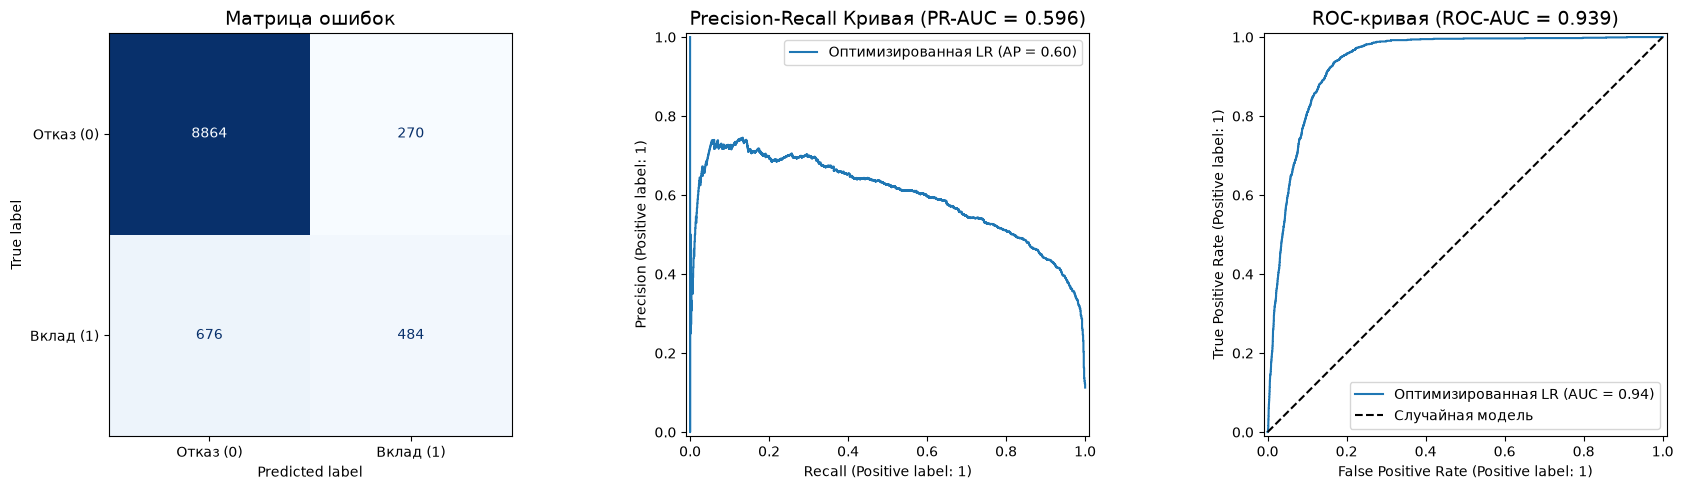

In [13]:
# 9. Построение комплексных графиков оценки
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# График 1: Матрица ошибок
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, 
    display_labels=["Отказ (0)", "Вклад (1)"], 
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Матрица ошибок", fontsize=14)
axes[0].grid(False)

# График 2: PR-кривая (важнейшая для дисбаланса)
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, ax=axes[1], name='Оптимизированная LR'
)
axes[1].set_title(f"Precision-Recall Кривая (PR-AUC = {pr_auc:.3f})", fontsize=14)
axes[1].legend(loc="upper right")

# График 3: ROC-кривая
RocCurveDisplay.from_predictions(
    y_test, y_proba, ax=axes[2], name='Оптимизированная LR'
)
axes[2].plot([0, 1], [0, 1], 'k--', label='Случайная модель')
axes[2].set_title(f"ROC-кривая (ROC-AUC = {roc_auc:.3f})", fontsize=14)
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

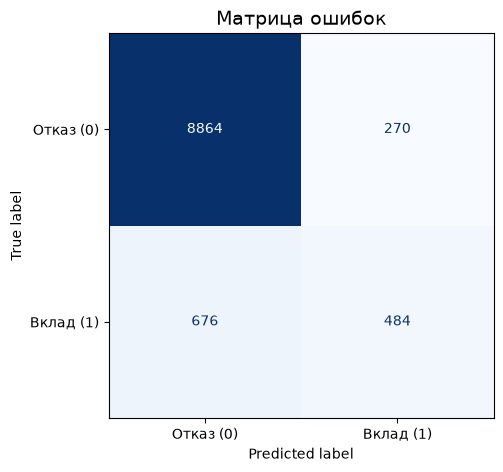

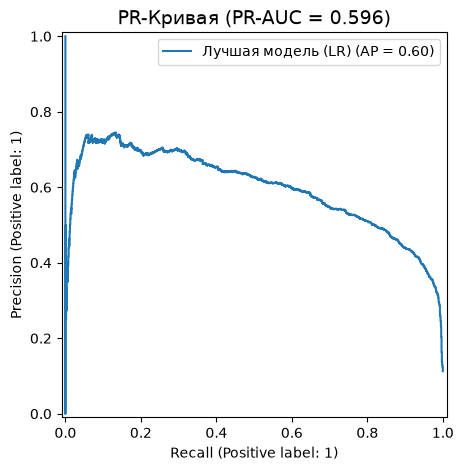

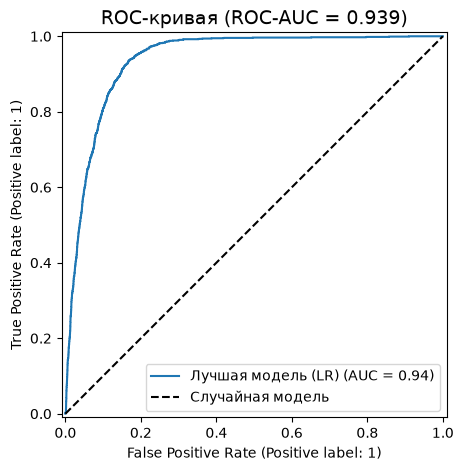

In [14]:
# График 1: Матрица ошибок
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Отказ (0)", "Вклад (1)"], cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Матрица ошибок", fontsize=14)
ax.grid(False)
plt.show()

# График 2: PR-кривая
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, name='Лучшая модель (LR)', ax=ax
)
ax.set_title(f"PR-Кривая (PR-AUC = {pr_auc:.3f})", fontsize=14)
ax.legend(loc="upper right")
plt.show()

# График 3: ROC-кривая
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test, y_proba, name='Лучшая модель (LR)', ax=ax
)
ax.plot([0, 1], [0, 1], 'k--', label='Случайная модель')
ax.set_title(f"ROC-кривая (ROC-AUC = {roc_auc:.3f})", fontsize=14)
ax.legend(loc="lower right")
plt.show()